In [2]:
import sys
from pathlib import Path

for p in [Path.cwd(), Path.cwd().parent, Path.cwd().parents[1]]:
    if (p / "prepare_data.py").exists():
        if str(p) not in sys.path:
            sys.path.insert(0, str(p))
        break
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from prepare_data import load_data, REQUIRED_COVARIATES

df = load_data()
train, test = load_data(split=True)
print(f"✓ Erfolgreich geladen!")
print(f"Gesamt analytische Kohorte: {df.shape[0]} Zeilen, {df.shape[1]} Spalten")
print(f"Train-Set: {train.shape[0]} | Test-Set: {test.shape[0]}")
print(f"KHK/Herzinfarkt-Prävalenz: {df['chd_mi'].mean():.1%}")

df[['nlr', 'log_nlr', 'crp', 'log_crp']].describe().T

✓ Erfolgreich geladen!
Gesamt analytische Kohorte: 4544 Zeilen, 35 Spalten
Train-Set: 3635 | Test-Set: 909
KHK/Herzinfarkt-Prävalenz: 7.4%


,count,mean,std,min,25%,50%,75%,max
nlr,4544.0,2.244751,1.181506,0.294737,1.519627,2.005054,2.679090,19.510638
log_nlr,4544.0,0.702950,0.451910,-1.221672,0.418465,0.695671,0.985477,2.970960
crp,4544.0,3.914930,7.431607,0.110000,0.820000,1.810000,4.230000,110.980000
log_crp,4544.0,0.647821,1.151417,-2.207275,-0.198451,0.593327,1.442202,4.709350


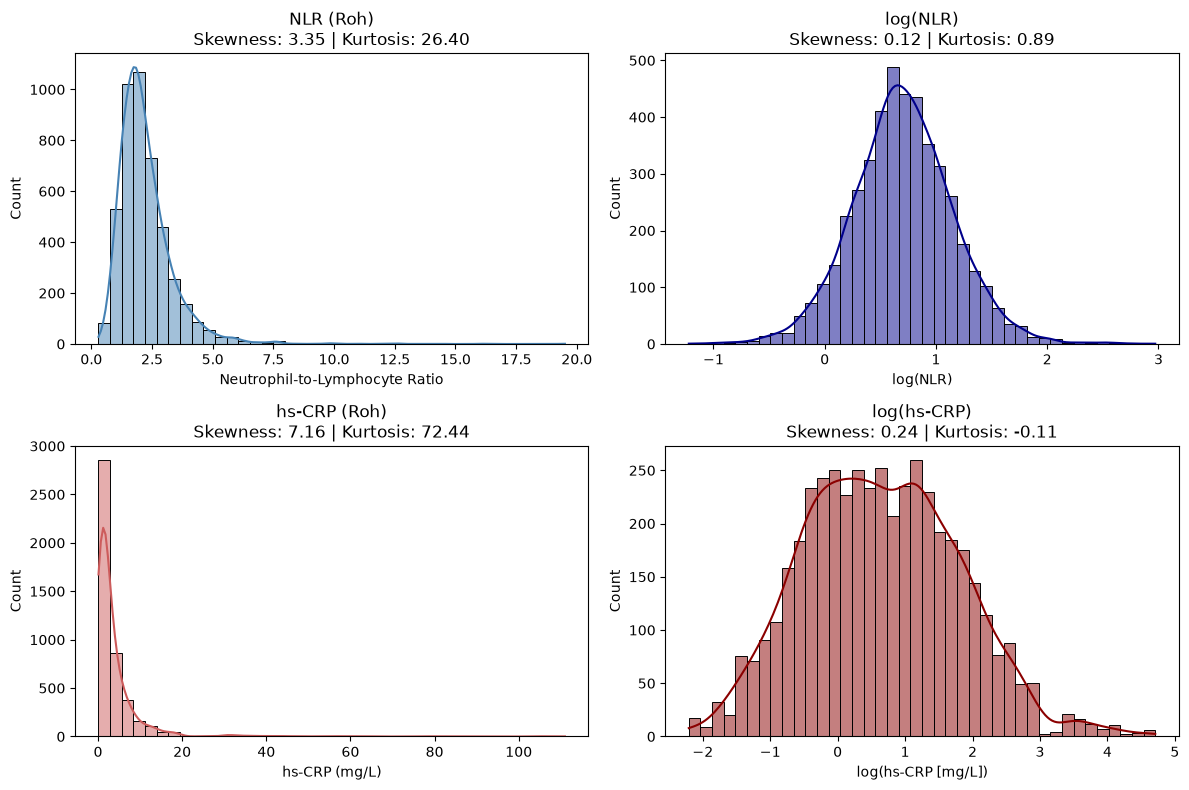

Interpretation für den Report:
-> Sowohl NLR als auch hs-CRP sind stark rechtsschief (Skewness >> 1).
-> Die Log-Transformation normalisiert die Verteilungen drastisch und rechtfertigt log(NLR) und log(CRP) für die Regressionsmodelle.


In [3]:
# %% [2. Verteilungsanalyse: NLR & hs-CRP (Roh vs. Log-Skala)]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
# 1. NLR Roh vs. Log
sns.histplot(df['nlr'], kde=True, ax=axes[0, 0], color='steelblue', bins=40)
axes[0, 0].set_title(f"NLR (Roh)\nSkewness: {stats.skew(df['nlr']):.2f} | Kurtosis: {stats.kurtosis(df['nlr']):.2f}")
axes[0, 0].set_xlabel("Neutrophil-to-Lymphocyte Ratio")
sns.histplot(df['log_nlr'], kde=True, ax=axes[0, 1], color='darkblue', bins=40)
axes[0, 1].set_title(f"log(NLR)\nSkewness: {stats.skew(df['log_nlr']):.2f} | Kurtosis: {stats.kurtosis(df['log_nlr']):.2f}")
axes[0, 1].set_xlabel("log(NLR)")
# 2. hs-CRP Roh vs. Log
sns.histplot(df['crp'], kde=True, ax=axes[1, 0], color='indianred', bins=40)
axes[1, 0].set_title(f"hs-CRP (Roh)\nSkewness: {stats.skew(df['crp']):.2f} | Kurtosis: {stats.kurtosis(df['crp']):.2f}")
axes[1, 0].set_xlabel("hs-CRP (mg/L)")
sns.histplot(df['log_crp'], kde=True, ax=axes[1, 1], color='darkred', bins=40)
axes[1, 1].set_title(f"log(hs-CRP)\nSkewness: {stats.skew(df['log_crp']):.2f} | Kurtosis: {stats.kurtosis(df['log_crp']):.2f}")
axes[1, 1].set_xlabel("log(hs-CRP [mg/L])")
plt.tight_layout()
plt.show()
print("Interpretation für den Report:")
print("-> Sowohl NLR als auch hs-CRP sind stark rechtsschief (Skewness >> 1).")
print("-> Die Log-Transformation normalisiert die Verteilungen drastisch und rechtfertigt log(NLR) und log(CRP) für die Regressionsmodelle.")

In [4]:
# %% [3. Table 1: Baseline-Charakteristika nach KHK/Herzinfarkt-Status]
cases = df[df['chd_mi'] == 1]
controls = df[df['chd_mi'] == 0]
t1_rows = []
# Kontinuierliche Variablen (Normalverteilt: Mean +/- SD, t-Test)
norm_vars = [
    ('Alter (Jahre)', 'age'),
    ('BMI (kg/m²)', 'bmi'),
    ('eGFR (mL/min/1.73m²)', 'egfr'),
    ('Systolischer RR (mmHg)', 'sbp'),
    ('Gesamtcholesterin (mg/dL)', 'total_chol'),
    ('HDL-Cholesterin (mg/dL)', 'hdl_chol'),
]
for label, col in norm_vars:
    m_case, sd_case = cases[col].mean(), cases[col].std()
    m_ctrl, sd_ctrl = controls[col].mean(), controls[col].std()
    p_val = stats.ttest_ind(cases[col].dropna(), controls[col].dropna(), equal_var=False).pvalue
    t1_rows.append({
        'Variable': label,
        'Kein KHK/MI (n = 4207)': f"{m_ctrl:.1f} ± {sd_ctrl:.1f}",
        'KHK/MI Fall (n = 337)': f"{m_case:.1f} ± {sd_case:.1f}",
        'Test': 'Welch t-Test',
        'p-Wert': f"{p_val:.4f}" if p_val >= 0.0001 else "< 0.0001"
    })
# Kontinuierliche Variablen (Schief: Median [IQR], Mann-Whitney-U-Test)
skew_vars = [
    ('NLR (Verhältnis)', 'nlr'),
    ('hs-CRP (mg/L)', 'crp'),
    ('Einkommens-Armuts-Verhältnis', 'income_pir'),
]
for label, col in skew_vars:
    q_case = cases[col].quantile([0.5, 0.25, 0.75])
    q_ctrl = controls[col].quantile([0.5, 0.25, 0.75])
    p_val = stats.mannwhitneyu(cases[col].dropna(), controls[col].dropna()).pvalue
    t1_rows.append({
        'Variable': label,
        'Kein KHK/MI (n = 4207)': f"{q_ctrl[0.5]:.2f} [{q_ctrl[0.25]:.2f}–{q_ctrl[0.75]:.2f}]",
        'KHK/MI Fall (n = 337)': f"{q_case[0.5]:.2f} [{q_case[0.25]:.2f}–{q_case[0.75]:.2f}]",
        'Test': 'Mann-Whitney-U',
        'p-Wert': f"{p_val:.4f}" if p_val >= 0.0001 else "< 0.0001"
    })
# Kategoriale Variablen (n (%), Chi-Quadrat-Test)
cat_vars = [
    ('Männlich', 'male', 1.0),
    ('Diabetes', 'diabetes', 1.0),
    ('Hypertonie', 'hypertension', 1.0),
    ('Lipidsenker / Statine', 'lipid_med', 1.0),
]
for label, col, val in cat_vars:
    n_ctrl = (controls[col] == val).sum()
    pct_ctrl = (controls[col] == val).mean() * 100
    n_case = (cases[col] == val).sum()
    pct_case = (cases[col] == val).mean() * 100
    
    contingency = pd.crosstab(df[col], df['chd_mi'])
    p_val = stats.chi2_contingency(contingency)[1]
    
    t1_rows.append({
        'Variable': label,
        'Kein KHK/MI (n = 4207)': f"{n_ctrl} ({pct_ctrl:.1f}%)",
        'KHK/MI Fall (n = 337)': f"{n_case} ({pct_case:.1f}%)",
        'Test': 'Chi-Quadrat',
        'p-Wert': f"{p_val:.4f}" if p_val >= 0.0001 else "< 0.0001"
    })
table1 = pd.DataFrame(t1_rows)
table1

,Variable,Kein KHK/MI (n = 4207),KHK/MI Fall (n = 337),Test,p-Wert
0,Alter (Jahre),52.8 ± 16.7,68.5 ± 9.7,Welch t-Test,< 0.0001
1,BMI (kg/m²),29.7 ± 7.1,31.0 ± 7.4,Welch t-Test,0.0016
2,eGFR (mL/min/1.73m²),92.5 ± 20.1,74.4 ± 21.4,Welch t-Test,< 0.0001
3,Systolischer RR (mmHg),122.2 ± 17.2,127.2 ± 21.3,Welch t-Test,< 0.0001
4,Gesamtcholesterin (mg/dL),190.9 ± 41.4,159.9 ± 44.7,Welch t-Test,< 0.0001
5,HDL-Cholesterin (mg/dL),55.1 ± 14.9,49.6 ± 12.7,Welch t-Test,< 0.0001
6,NLR (Verhältnis),1.98 [1.50–2.64],2.38 [1.84–3.28],Mann-Whitney-U,< 0.0001
7,hs-CRP (mg/L),1.81 [0.81–4.21],2.07 [0.93–4.63],Mann-Whitney-U,0.1990
8,Einkommens-Armuts-Verhältnis,3.00 [1.55–5.00],2.47 [1.38–4.22],Mann-Whitney-U,0.0003
9,Männlich,1822 (43.3%),217 (64.4%),Chi-Quadrat,< 0.0001


In [5]:
# %% [4. Table 2: Verschachtelte multivariable logistische Regression (statsmodels)]
import statsmodels.api as sm
import statsmodels.formula.api as smf
# 1. Z-Standardisierung der Marker (OR pro 1 SD Anstieg)
df_reg = df.copy()
df_reg['nlr_z'] = (df_reg['log_nlr'] - df_reg['log_nlr'].mean()) / df_reg['log_nlr'].std()
df_reg['crp_z'] = (df_reg['log_crp'] - df_reg['log_crp'].mean()) / df_reg['log_crp'].std()
# 2. Modellformeln definieren
cov_m0 = "age + male"
cov_m1 = f"{cov_m0} + bmi + C(race_eth) + income_pir"
cov_m2 = f"{cov_m1} + C(smoking) + diabetes + hypertension + total_chol + hdl_chol + egfr + lipid_med"
models_specs = [
    ("Unadjustiert", ""),
    ("Modell 0 (+ Demografie)", f"+ {cov_m0}"),
    ("Modell 1 (+ Sozioökon./BMI)", f"+ {cov_m1}"),
    ("Modell 2 (+ Risikofakt./Lipidmed)", f"+ {cov_m2}"),
]
results_table = []
# Für jeden Marker einzeln durch M0 -> M2 fitten
for marker_name, marker_col in [("log(NLR) pro SD", "nlr_z"), ("log(hs-CRP) pro SD", "crp_z")]:
    row = {"Exposition": marker_name}
    for model_name, formula_covs in models_specs:
        formula = f"chd_mi ~ {marker_col} {formula_covs}"
        fit = smf.logit(formula, data=df_reg).fit(disp=False)
        
        coef = fit.params[marker_col]
        se = fit.bse[marker_col]
        pval = fit.pvalues[marker_col]
        
        # Odds Ratio & 95% Konfidenzintervall
        or_val = np.exp(coef)
        ci_lower = np.exp(coef - 1.96 * se)
        ci_upper = np.exp(coef + 1.96 * se)
        
        p_str = "< 0.001" if pval < 0.001 else f"= {pval:.3f}"
        sig = "*" if pval < 0.025 else ""  # Bonferroni-Schwelle: 0.05 / 2 = 0.025 (Tutorial 4)
        
        row[model_name] = f"{or_val:.2f} ({ci_lower:.2f}–{ci_upper:.2f}){sig} [p {p_str}]"
    
    results_table.append(row)
# 3. Modell 3: Beide Marker gemeinsam in Modell 2 (Mutual Adjustment)
fit_m3 = smf.logit(f"chd_mi ~ nlr_z + crp_z + {cov_m2}", data=df_reg).fit(disp=False)
m3_res = {}
for marker_name, marker_col in [("log(NLR) pro SD", "nlr_z"), ("log(hs-CRP) pro SD", "crp_z")]:
    coef = fit_m3.params[marker_col]
    se = fit_m3.bse[marker_col]
    pval = fit_m3.pvalues[marker_col]
    or_val = np.exp(coef)
    ci_lower = np.exp(coef - 1.96 * se)
    ci_upper = np.exp(coef + 1.96 * se)
    p_str = "< 0.001" if pval < 0.001 else f"= {pval:.3f}"
    sig = "*" if pval < 0.025 else ""
    m3_res[marker_name] = f"{or_val:.2f} ({ci_lower:.2f}–{ci_upper:.2f}){sig} [p {p_str}]"
results_df = pd.DataFrame(results_table)
results_df["Modell 3 (Vollständig: M2 + beide Marker)"] = results_df["Exposition"].map(m3_res)
# Bonferroni-Erklärung anzeigen
print("Hinweis: * bedeutet statistisch signifikant nach Bonferroni-Korrektur (p < 0.025 für 2 Co-Primary Endpunkte, Tutorial 4 Slide 11)")
results_df

Hinweis: * bedeutet statistisch signifikant nach Bonferroni-Korrektur (p < 0.025 für 2 Co-Primary Endpunkte, Tutorial 4 Slide 11)


,Exposition,Unadjustiert,Modell 0 (+ Demografie),Modell 1 (+ Sozioökon./BMI),Modell 2 (+ Risikofakt./Lipidmed),Modell 3 (Vollständig: M2 + beide Marker)
0,log(NLR) pro SD,1.59 (1.42–1.77)* [p < 0.001],1.26 (1.13–1.42)* [p < 0.001],1.24 (1.10–1.40)* [p < 0.001],1.18 (1.04–1.34)* [p = 0.011],1.18 (1.04–1.35)* [p = 0.011]
1,log(hs-CRP) pro SD,1.07 (0.95–1.19) [p = 0.254],1.14 (1.01–1.29) [p = 0.039],0.99 (0.86–1.13) [p = 0.853],1.01 (0.88–1.17) [p = 0.878],0.98 (0.85–1.13) [p = 0.784]


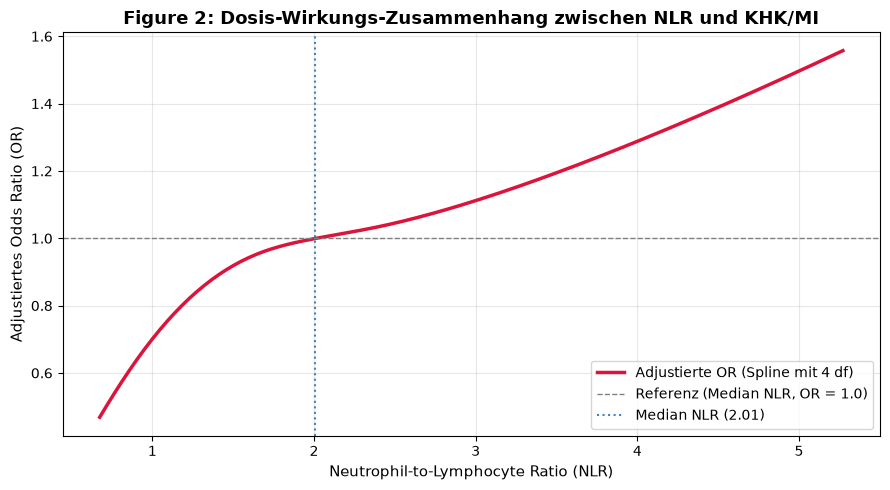

In [6]:
# %% [5. Figure 2: Dosis-Wirkungs-Kurve von NLR via Splines (Restricted Cubic Splines)]
from patsy import dmatrix
# Spline-Modell für NLR berechnen (adjustiert für Modell 1 Kovariaten)
spline_formula = f"chd_mi ~ cr(log_nlr, df=4) + age + male + bmi + income_pir"
fit_spline = smf.logit(spline_formula, data=df_reg).fit(disp=False)
# Vorhersage über den Bereich von NLR (von 1. bis 99. Perzentil)
nlr_range = np.linspace(df_reg['nlr'].quantile(0.01), df_reg['nlr'].quantile(0.98), 200)
pred_df = pd.DataFrame({
    'log_nlr': np.log(nlr_range),
    'age': df_reg['age'].mean(),
    'male': 0.5,
    'bmi': df_reg['bmi'].mean(),
    'income_pir': df_reg['income_pir'].mean()
})
# Vorhergesagte Wahrscheinlichkeit und Odds Ratio relativ zum Median
pred_prob = fit_spline.predict(pred_df)
ref_idx = np.argmin(np.abs(nlr_range - df_reg['nlr'].median()))
pred_odds = pred_prob / (1 - pred_prob)
ref_odds = pred_odds.iloc[ref_idx]
pred_or = pred_odds / ref_odds
plt.figure(figsize=(9, 5))
plt.plot(nlr_range, pred_or, color='crimson', lw=2.5, label='Adjustierte OR (Spline mit 4 df)')
plt.axhline(1.0, color='gray', linestyle='--', lw=1, label='Referenz (Median NLR, OR = 1.0)')
plt.axvline(df_reg['nlr'].median(), color='steelblue', linestyle=':', label=f"Median NLR ({df_reg['nlr'].median():.2f})")
plt.title("Figure 2: Dosis-Wirkungs-Zusammenhang zwischen NLR und KHK/MI", fontsize=13, fontweight='bold')
plt.xlabel("Neutrophil-to-Lymphocyte Ratio (NLR)", fontsize=11)
plt.ylabel("Adjustiertes Odds Ratio (OR)", fontsize=11)
plt.legend(frameon=True)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()